# Лабораторная № 1. Регрессия

Предсказываем `quality` по химическим свойствам вина. Данные: [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality), Cortez et al., 2009 (CC BY 4.0). Объединяем белое и красное вино; `is_red` — признак красного вина


In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.kernel_approximation import Nystroem
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans"})
pd.set_option("display.precision", 4)
path = Path("data") if Path("data/winequality-red.csv").exists() else Path("regression/data")
red = pd.read_csv(path / "winequality-red.csv", sep=";").assign(is_red=1)
white = pd.read_csv(path / "winequality-white.csv", sep=";").assign(is_red=0)
data = pd.concat([red, white], ignore_index=True)
print("Размер:", data.shape, "| Пропусков:", data.isna().sum().sum())
print("Числовых столбцов:", len(data.select_dtypes("number").columns))
print("Полных повторов сверх первого вхождения:", data.duplicated().sum())

Размер: (6497, 13) | Пропусков: 0
Числовых столбцов: 13
Полных повторов сверх первого вхождения: 1177


## 1. Разбиение и анализ данных



Train: 5222 | Test: 1275


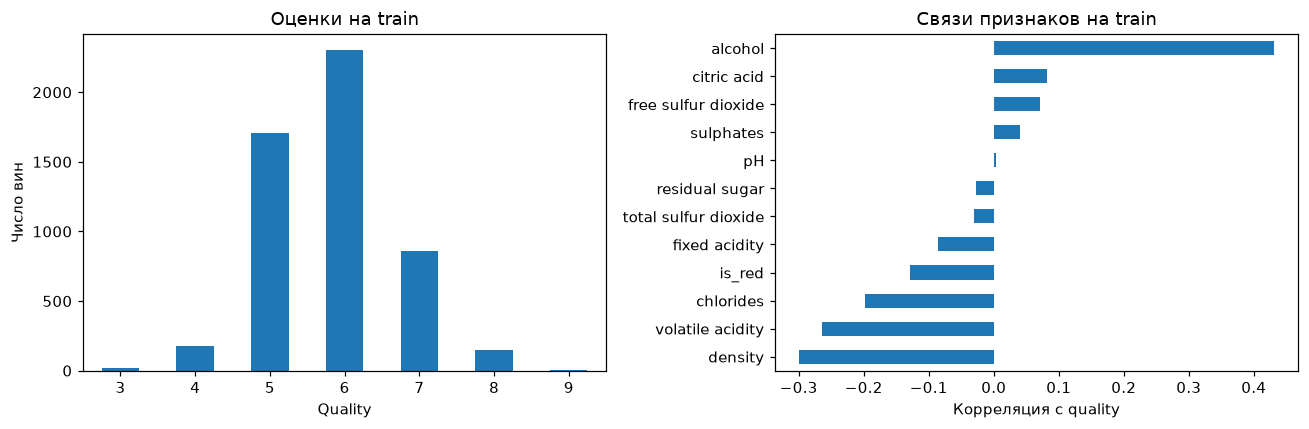

In [12]:
X, y = data.drop(columns="quality"), data["quality"]
groups = pd.util.hash_pandas_object(X, index=False)
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(split.split(X, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
fit_idx, val_idx = next(split.split(X_train, groups=groups.iloc[train_idx]))
print("Train:", len(X_train), "| Test:", len(X_test))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y_train.value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(xlabel="Quality", ylabel="Число вин", title="Оценки на train")
corr = X_train.corrwith(y_train).sort_values()
corr.plot.barh(ax=axes[1])
axes[1].set(xlabel="Корреляция с quality", title="Связи признаков на train")
plt.tight_layout()
plt.show()

**Вывод.** В train 5222 строки, в test 1275. Оценки 5–6 преобладают, другие оценки крайние редки. С качеством положительно связан alcohol (**0.431**), отрицательно — volatile acidity (**−0.264**) и density (**−0.300**). Эти признаки стоит учитывать, но с
лабая корреляция остальных не исключает нелинейной связи.

## 2. Baseline и обучаемые модели
`Ridge` — линейная регрессия с L2-регуляризацией. После RBF-преобразования она может описывать нелинейные зависимости. Далее идут Random Forest и Gradient Boosting.

In [13]:
rbf_ridge = make_pipeline(
    StandardScaler(),
    Nystroem(kernel="rbf", gamma=0.05, n_components=1200, random_state=42),
    Ridge(alpha=1),
)
forest = RandomForestRegressor(
    n_estimators=500, max_features=0.7, random_state=42, n_jobs=1,
)
boosting = GradientBoostingRegressor(
    n_estimators=1000, max_depth=3, learning_rate=0.02,
    subsample=0.7, min_samples_leaf=3, random_state=42,
)

validation_models = {
    "RBF + Ridge": rbf_ridge,
    "Random Forest": forest,
    "Gradient Boosting (base)": boosting,
}
validation_rmse, validation_predictions = {}, {}
for name, model in validation_models.items():
    model.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
    prediction = model.predict(X_train.iloc[val_idx])
    validation_predictions[name] = prediction
    validation_rmse[name] = root_mean_squared_error(y_train.iloc[val_idx], prediction)
validation_predictions["Gradient Boosting"] = (
    0.4 * validation_predictions["RBF + Ridge"] +
    0.6 * validation_predictions["Gradient Boosting (base)"]
)
validation_rmse["Gradient Boosting"] = root_mean_squared_error(
    y_train.iloc[val_idx], validation_predictions["Gradient Boosting"]
)

baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
for model in [rbf_ridge, forest, boosting]:
    model.fit(X_train, y_train)

predictions = {
    "Baseline": baseline.predict(X_test),
    "RBF + Ridge": rbf_ridge.predict(X_test),
    "Random Forest": forest.predict(X_test),
}
predictions["Gradient Boosting"] = (
    0.4 * predictions["RBF + Ridge"] + 0.6 * boosting.predict(X_test)
)

rows = []
for name, prediction in predictions.items():
    rows.append({"Модель": name,
                 "RMSE": root_mean_squared_error(y_test, prediction),
                 "MAE": mean_absolute_error(y_test, prediction)})
results = pd.DataFrame(rows).set_index("Модель")
best_name = min(validation_rmse, key=validation_rmse.get)
display(results)
print("Лучшая модель по validation:", best_name)
print("Validation RMSE:", validation_rmse)

,RMSE,MAE
Модель,,
Baseline,0.8968,0.7072
RBF + Ridge,0.6965,0.5388
Random Forest,0.6944,0.5273
Gradient Boosting,0.6933,0.5335


Лучшая модель по validation: Gradient Boosting
Validation RMSE: {'RBF + Ridge': 0.7273753739114257, 'Random Forest': 0.7205457185806058, 'Gradient Boosting (base)': 0.7206080026633263, 'Gradient Boosting': 0.7168131568269054}


## 3. Важность признаков


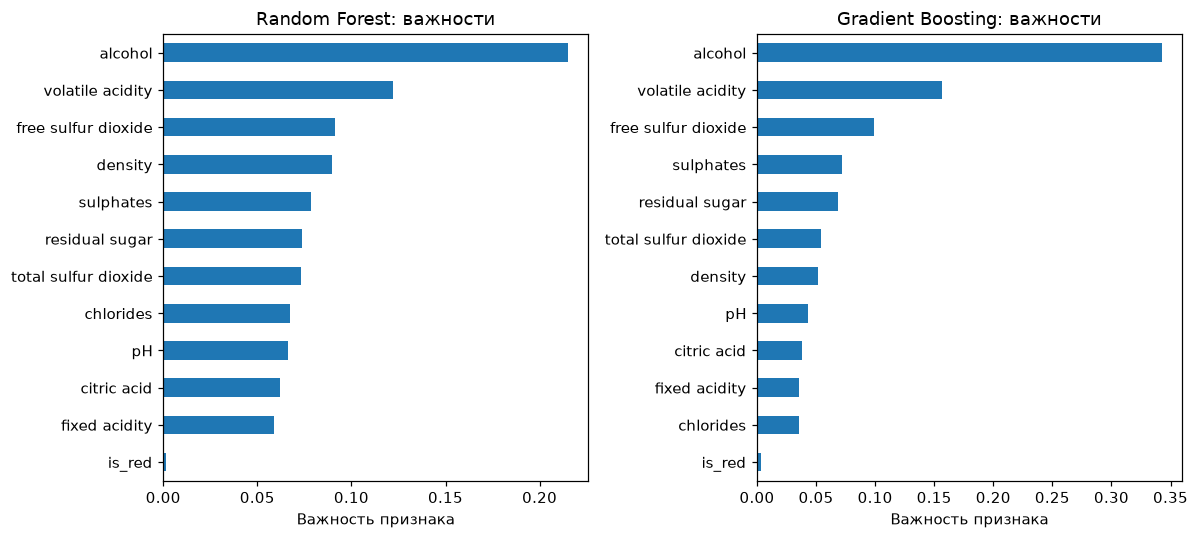

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, model, title in [
    (axes[0], forest, "Random Forest: важности"),
    (axes[1], boosting, "Gradient Boosting: важности"),
]:
    pd.Series(model.feature_importances_, index=X.columns).sort_values().plot.barh(ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Важность признака")
plt.tight_layout()
plt.show()

**Вывод.** У леса и бустинга лидируют **alcohol, volatile acidity, free sulfur dioxide**. Первые два согласуются с первичным анализом: alcohol положительно, а volatile acidity отрицательно связаны с quality. Важность не доказывает причинность: свойства взаимосвязаны, а часть факторов, влияющих на оценку вина, в данных отсутствует.

## 4. Анализ ошибок выбранной модели

Остаток = истинное quality − прогноз. Положительный остаток означает недооценку. После анализа test модель не меняем.

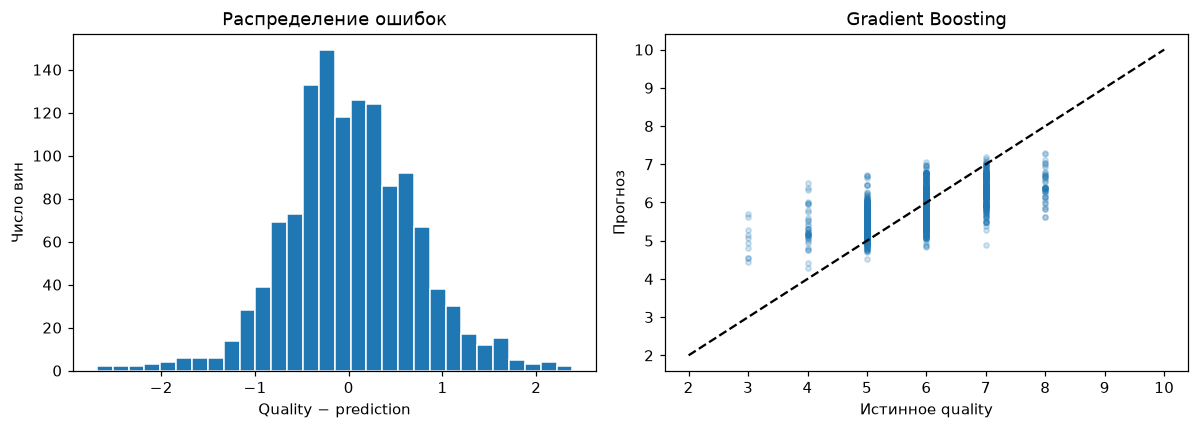

,count,MAE,RMSE
quality,,,
3,10,2.0081,2.0503
4,37,1.3515,1.4409
5,428,0.4572,0.5616
6,534,0.3616,0.4440
7,222,0.6885,0.7936
8,44,1.5564,1.6086


,quality,prediction,abs_error,fixed acidity,residual sugar,alcohol
3649,3,5.6871,2.6871,11.8,11.1,9.7
5409,3,5.6108,2.6108,6.8,15.1,10.5
6107,4,6.5102,2.5102,5.8,2.6,11.5


In [15]:
errors = X_test.assign(quality=y_test, prediction=predictions[best_name])
errors["residual"] = errors["quality"] - errors["prediction"]
errors["abs_error"] = errors["residual"].abs()
errors["squared_error"] = errors["residual"] ** 2
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(errors["residual"], bins=30, edgecolor="white")
axes[0].set(xlabel="Quality − prediction", ylabel="Число вин", title="Распределение ошибок")
axes[1].scatter(y_test, errors["prediction"], alpha=0.2, s=12)
axes[1].plot([2, 10], [2, 10], "k--")
axes[1].set(xlabel="Истинное quality", ylabel="Прогноз", title=best_name)
plt.tight_layout()
plt.show()

by_quality = errors.groupby("quality").agg(
    count=("residual", "size"), MAE=("abs_error", "mean"), MSE=("squared_error", "mean")
)
by_quality["RMSE"] = np.sqrt(by_quality.pop("MSE"))
display(by_quality)
worst = errors.nlargest(3, "abs_error")
display(worst[["quality", "prediction", "abs_error", "fixed acidity", "residual sugar", "alcohol"]])

**Вывод.** Ошибки неодинаковы: модель лучше всего работает на частых оценках 5–6. У редких 3, 4 и 8 примеров мало, поэтому прогнозы сильнее тянутся к средним значениям.